# Cyber Attack Detection Using Ensemble Learning

**Dataset:** UNSW-NB15, official train/test partition (Moustafa & Slay, 2015)

Compares a baseline Decision Tree against three ensemble methods (Random Forest, XGBoost, soft-voting ensemble) on two tasks:

| Task | Target | Classes |
|---|---|---|
| **A. Binary** | `label` | Normal vs Attack |
| **B. Multi-class** | `attack_cat` | Normal + 9 attack types (10 classes) |
| **C. Multi-class + SMOTE** | `attack_cat` | Same 10 classes, rare classes oversampled in training |
| **D. PCA** | both | Binary and multi-class on PCA-reduced features (95% variance) |

Place `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv` in a `data/` folder next to this notebook.

## 1. Setup

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
from xgboost import XGBClassifier

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
RANDOM_STATE = 42

## 2. Load data

In [2]:
train_df = pd.read_csv("data/UNSW_NB15_training-set.csv")
test_df = pd.read_csv("data/UNSW_NB15_testing-set.csv")
print(f"Train: {len(train_df):,} rows | Test: {len(test_df):,} rows | {train_df.shape[1]} columns")
pd.concat([train_df["attack_cat"].value_counts().rename("train"),
           test_df["attack_cat"].value_counts().rename("test")], axis=1)

Train: 175,341 rows | Test: 82,332 rows | 45 columns


,train,test
attack_cat,,
Normal,56000,37000
Generic,40000,18871
Exploits,33393,11132
Fuzzers,18184,6062
DoS,12264,4089
Reconnaissance,10491,3496
Analysis,2000,677
Backdoor,1746,583
Shellcode,1133,378


Class sizes range from 56,000 (Normal) down to 130 (Worms) in training. This imbalance is the main reason multi-class performance is much weaker than binary.

## 3. Preprocessing (shared by both tasks)

- Drop `id`. `label` and `attack_cat` are the two targets.
- Label-encode `proto`, `service`, `state`. Encoders are fit on train+test categories together, because the test set contains `state` values (`CLO`, `ACC`) absent from training. This builds a vocabulary only; no target information is used.
- `StandardScaler` fit on training data only.
- `attack_cat` is integer-encoded (alphabetical) for the multi-class task.

In [3]:
CAT_COLS = ["proto", "service", "state"]
train_x = train_df.drop(columns=["id", "label", "attack_cat"]).copy()
test_x = test_df.drop(columns=["id", "label", "attack_cat"]).copy()

encoders = {}
for col in CAT_COLS:
    le = LabelEncoder()
    le.fit(pd.concat([train_x[col], test_x[col]], axis=0))
    train_x[col] = le.transform(train_x[col])
    test_x[col] = le.transform(test_x[col])
    encoders[col] = le

feature_names = list(train_x.columns)
scaler = StandardScaler()
X_train = scaler.fit_transform(train_x)     # fit on train only
X_test = scaler.transform(test_x)

label_encoder = LabelEncoder()
label_encoder.fit(pd.concat([train_df["attack_cat"], test_df["attack_cat"]]))
class_names = list(label_encoder.classes_)

y_train_bin, y_test_bin = train_df["label"].values, test_df["label"].values
y_train_multi = label_encoder.transform(train_df["attack_cat"])
y_test_multi = label_encoder.transform(test_df["attack_cat"])

print("Features:", X_train.shape[1])
print("Classes:", class_names)

Features: 42
Classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


## 4. Model factory

Same four models for both tasks. XGBoost's logging metric switches to `mlogloss` for multi-class.

In [4]:
def train_models(task, X, y):
    xgb_metric = "logloss" if task == "binary" else "mlogloss"
    models = {
        "decision_tree": DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=10),
        "random_forest": RandomForestClassifier(n_estimators=100, max_depth=15,
                                                random_state=RANDOM_STATE, n_jobs=-1),
        "xgboost": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                                 random_state=RANDOM_STATE, eval_metric=xgb_metric, n_jobs=-1),
    }
    times = {}
    for name, m in models.items():
        t0 = time.time(); m.fit(X, y); times[name] = time.time() - t0
    t0 = time.time()
    voting = VotingClassifier(estimators=[("dt", models["decision_tree"]),
                                          ("rf", models["random_forest"]),
                                          ("xgb", models["xgboost"])],
                              voting="soft", n_jobs=-1)
    voting.fit(X, y)
    times["voting_ensemble"] = time.time() - t0
    models["voting_ensemble"] = voting
    return models, times

# Part A: Binary classification (Normal vs Attack)

In [5]:
bin_models, bin_times = train_models("binary", X_train, y_train_bin)

rows = []
for name, m in bin_models.items():
    p = m.predict(X_test)
    rows.append(dict(model=name, accuracy=accuracy_score(y_test_bin, p),
                     precision=precision_score(y_test_bin, p), recall=recall_score(y_test_bin, p),
                     f1=f1_score(y_test_bin, p), train_time_s=bin_times[name]))
bin_results = pd.DataFrame(rows).round(4)
bin_results

,model,accuracy,precision,recall,f1,train_time_s
0,decision_tree,0.8439,0.7871,0.9822,0.8739,1.5287
1,random_forest,0.8647,0.8081,0.9892,0.8895,21.7120
2,xgboost,0.8739,0.8204,0.9869,0.8960,5.1684
3,voting_ensemble,0.8662,0.8112,0.9866,0.8904,27.3557


XGBoost has the best F1. All three ensembles beat the single Decision Tree, and recall stays above 0.98 for every model, so few real attacks are missed. Precision is lower (about 0.79 to 0.82) because the official test set has a different class balance than training.

In [6]:
print("Confusion matrix - XGBoost (rows=actual, cols=predicted; 0=Normal, 1=Attack)")
print(confusion_matrix(y_test_bin, bin_models["xgboost"].predict(X_test)))

Confusion matrix - XGBoost (rows=actual, cols=predicted; 0=Normal, 1=Attack)
[[27207  9793]
 [  592 44740]]


# Part B: Multi-class classification (10 classes)

In [7]:
multi_models, multi_times = train_models("multiclass", X_train, y_train_multi)

rows, preds = [], {}
for name, m in multi_models.items():
    p = m.predict(X_test); preds[name] = p
    rows.append(dict(model=name,
                     accuracy=accuracy_score(y_test_multi, p),
                     macro_precision=precision_score(y_test_multi, p, average="macro", zero_division=0),
                     macro_recall=recall_score(y_test_multi, p, average="macro", zero_division=0),
                     macro_f1=f1_score(y_test_multi, p, average="macro", zero_division=0),
                     weighted_f1=f1_score(y_test_multi, p, average="weighted", zero_division=0),
                     train_time_s=multi_times[name]))
multi_results = pd.DataFrame(rows).round(4)
best_multi = multi_results.sort_values("macro_f1", ascending=False).iloc[0]["model"]
print("Best by macro-F1:", best_multi)
multi_results

Best by macro-F1: xgboost


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,train_time_s
0,decision_tree,0.7031,0.5047,0.4840,0.4431,0.7286,1.5951
1,random_forest,0.7676,0.5800,0.5019,0.4734,0.7742,23.3152
2,xgboost,0.7691,0.5422,0.5415,0.5023,0.7804,22.9031
3,voting_ensemble,0.7565,0.5438,0.5083,0.4708,0.7703,50.1087


**Why macro-F1 is the headline metric here:** accuracy and weighted-F1 are dominated by the big classes (Normal, Generic, Exploits). Macro-F1 averages every class equally, so it shows how the model does on rare attacks.

### Per-class report (best model)

In [8]:
print(classification_report(y_test_multi, preds[best_multi], target_names=class_names, zero_division=0))

                precision    recall  f1-score   support

      Analysis       0.05      0.06      0.06       677
      Backdoor       0.04      0.10      0.06       583
           DoS       0.50      0.08      0.14      4089
      Exploits       0.59      0.86      0.70     11132
       Fuzzers       0.32      0.61      0.42      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.97      0.76      0.85     37000
Reconnaissance       0.93      0.81      0.87      3496
     Shellcode       0.30      0.75      0.43       378
         Worms       0.72      0.41      0.52        44

      accuracy                           0.77     82332
     macro avg       0.54      0.54      0.50     82332
  weighted avg       0.83      0.77      0.78     82332



### Per-class F1 across all models

In [9]:
f1_table = pd.DataFrame({name: f1_score(y_test_multi, p, average=None, zero_division=0)
                         for name, p in preds.items()}, index=class_names).round(3)
f1_table

,decision_tree,random_forest,xgboost,voting_ensemble
Analysis,0.028,0.014,0.056,0.041
Backdoor,0.081,0.064,0.057,0.058
DoS,0.123,0.120,0.137,0.136
Exploits,0.669,0.702,0.703,0.696
Fuzzers,0.334,0.400,0.416,0.395
Generic,0.977,0.982,0.983,0.982
Normal,0.769,0.844,0.852,0.836
Reconnaissance,0.831,0.860,0.865,0.856
Shellcode,0.365,0.517,0.432,0.449
Worms,0.255,0.231,0.522,0.259


### Confusion matrix (best model, row-normalised)

Each row shows where the actual class got predicted.

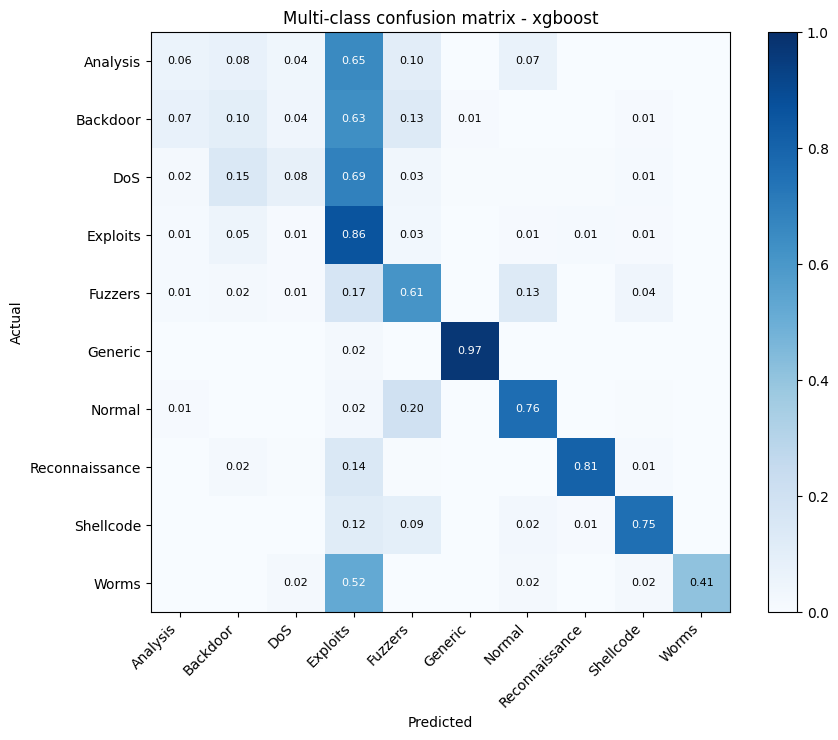

In [10]:
cm = confusion_matrix(y_test_multi, preds[best_multi])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(class_names, rotation=45, ha="right"); ax.set_yticklabels(class_names)
for i in range(10):
    for j in range(10):
        if cm_norm[i, j] >= 0.01:
            ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Multi-class confusion matrix - {best_multi}")
fig.colorbar(im, ax=ax, fraction=0.046); fig.tight_layout()
plt.show()

### What the results show

- **Large, distinctive classes work well:** Generic (F1 about 0.98), Reconnaissance (about 0.87), Normal (about 0.85).
- **Exploits acts as a catch-all.** Most DoS, Analysis, Backdoor and Worms records are predicted as Exploits (see the matrix), so those classes have very low recall.
- **Analysis, Backdoor and DoS are close to unusable** (F1 between 0.06 and 0.14). Analysis and Backdoor have only about 2,000 and 1,700 training rows, and DoS traffic overlaps heavily with Exploits.
- **Macro-F1 (about 0.50) is far below weighted-F1 (about 0.78):** the gap is the class-imbalance problem in one number.
- **The voting ensemble does not beat XGBoost** on multi-class either. Averaging in the weaker Decision Tree and Random Forest probabilities dilutes XGBoost's better rare-class recall.

# Part C: Multi-class with SMOTE (class-imbalance handling)

The rare attack classes (Analysis, Backdoor, Shellcode, Worms) are tiny, so SMOTE creates synthetic training examples for them.

Design choices:
- **Training set only.** The test set is never resampled, so evaluation stays honest.
- **SMOTENC, not plain SMOTE.** `proto`, `service` and `state` are integer category codes; plain SMOTE would interpolate between codes and invent meaningless categories.
- **A floor, not full balancing.** Every class smaller than 10,000 rows is raised to 10,000 (the size of the mid-sized classes). Fully balancing to 56,000 per class would mean about 560,000 rows and very slow training. The floor was fixed before looking at results.
- Resampling is done on unscaled features, then the original scaler is applied, so the saved scaler stays valid for the demo.

In [11]:
from imblearn.over_sampling import SMOTENC

SMOTE_FLOOR = 10_000
counts = pd.Series(y_train_multi).value_counts()
strategy = {int(c): SMOTE_FLOOR for c, n in counts.items() if n < SMOTE_FLOOR}
cat_idx = [list(train_x.columns).index(c) for c in CAT_COLS]

smote = SMOTENC(categorical_features=cat_idx, sampling_strategy=strategy,
                k_neighbors=5, random_state=RANDOM_STATE)
X_res, y_res = smote.fit_resample(train_x, y_train_multi)
X_train_smote = scaler.transform(X_res)

pd.DataFrame({"before": pd.Series(y_train_multi).value_counts().sort_index().values,
              "after": pd.Series(y_res).value_counts().sort_index().values}, index=class_names)

,before,after
Analysis,2000,10000
Backdoor,1746,10000
DoS,12264,12264
Exploits,33393,33393
Fuzzers,18184,18184
Generic,40000,40000
Normal,56000,56000
Reconnaissance,10491,10491
Shellcode,1133,10000
Worms,130,10000


In [12]:
smote_models, smote_times = train_models("multiclass", X_train_smote, y_res)

rows, smote_preds = [], {}
for name, m in smote_models.items():
    p = m.predict(X_test); smote_preds[name] = p
    rows.append(dict(model=name,
                     accuracy=accuracy_score(y_test_multi, p),
                     macro_precision=precision_score(y_test_multi, p, average="macro", zero_division=0),
                     macro_recall=recall_score(y_test_multi, p, average="macro", zero_division=0),
                     macro_f1=f1_score(y_test_multi, p, average="macro", zero_division=0),
                     weighted_f1=f1_score(y_test_multi, p, average="weighted", zero_division=0),
                     train_time_s=smote_times[name]))
smote_results = pd.DataFrame(rows).round(4)
smote_results

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,train_time_s
0,decision_tree,0.6637,0.4402,0.5579,0.3983,0.7046,2.0937
1,random_forest,0.7276,0.4917,0.6061,0.4449,0.7574,30.8355
2,xgboost,0.7480,0.4772,0.6028,0.4584,0.7723,29.4499
3,voting_ensemble,0.7278,0.4836,0.5944,0.4438,0.7558,61.4517


### Before vs after SMOTE

In [13]:
cmp = multi_results.set_index("model")[["accuracy", "macro_precision", "macro_recall", "macro_f1"]].join(
      smote_results.set_index("model")[["accuracy", "macro_precision", "macro_recall", "macro_f1"]],
      lsuffix="_before", rsuffix="_after")
cmp

,accuracy_before,macro_precision_before,macro_recall_before,macro_f1_before,accuracy_after,macro_precision_after,macro_recall_after,macro_f1_after
model,,,,,,,,
decision_tree,0.7031,0.5047,0.4840,0.4431,0.6637,0.4402,0.5579,0.3983
random_forest,0.7676,0.5800,0.5019,0.4734,0.7276,0.4917,0.6061,0.4449
xgboost,0.7691,0.5422,0.5415,0.5023,0.7480,0.4772,0.6028,0.4584
voting_ensemble,0.7565,0.5438,0.5083,0.4708,0.7278,0.4836,0.5944,0.4438


In [14]:
# Per-class view for the best model: precision, recall, F1 before vs after
b = best_multi
rows = []
for c, cname in enumerate(class_names):
    def prf(pred):
        return (precision_score(y_test_multi, pred, labels=[c], average=None, zero_division=0)[0],
                recall_score(y_test_multi, pred, labels=[c], average=None, zero_division=0)[0],
                f1_score(y_test_multi, pred, labels=[c], average=None, zero_division=0)[0])
    pb, rb, fb = prf(preds[b]); pa, ra, fa = prf(smote_preds[b])
    rows.append(dict(cls=cname, P_before=pb, P_after=pa, R_before=rb, R_after=ra, F1_before=fb, F1_after=fa))
pd.DataFrame(rows).set_index("cls").round(3)

,P_before,P_after,R_before,R_after,F1_before,F1_after
cls,,,,,,
Analysis,0.052,0.031,0.062,0.111,0.056,0.049
Backdoor,0.040,0.052,0.101,0.254,0.057,0.086
DoS,0.503,0.522,0.079,0.069,0.137,0.122
Exploits,0.595,0.628,0.860,0.783,0.703,0.697
Fuzzers,0.316,0.316,0.611,0.566,0.416,0.406
Generic,0.996,0.997,0.970,0.968,0.983,0.982
Normal,0.965,0.967,0.762,0.742,0.852,0.840
Reconnaissance,0.933,0.941,0.807,0.805,0.865,0.867
Shellcode,0.303,0.195,0.754,0.934,0.432,0.323


**Finding: SMOTE did not improve macro-F1; it made it worse for all four models.**

- **Recall rose, precision fell by more.** Macro-recall went up (XGBoost about 0.54 to 0.60) but macro-precision went down (about 0.54 to 0.48), so macro-F1 dropped (about 0.50 to 0.46).
- **Worms shows it most clearly:** recall roughly doubled (0.41 to 0.80) but precision collapsed (0.72 to 0.12), so F1 fell. With only 130 real Worms rows, 10,000 synthetic ones are interpolations of a handful of real points, so the model over-predicts the class.
- **Backdoor is the one clear F1 gain** (about 0.06 to 0.09), though still very low.
- **DoS is unchanged** (about 0.12). It already had 12,264 rows so SMOTE never touched it; its problem is overlap with Exploits, not too few examples.
- **Analysis and Backdoor stay near unusable.** Their traffic is not separable from other classes with these features; more synthetic copies do not add information.

### Sensitivity check: does a gentler floor help? (XGBoost only)

This is analysis, not model selection: the main setting above stays at 10,000.

In [15]:
rows = []
for floor in [None, 3000, 5000, 10000]:
    if floor is None:
        Xf, yf = X_train, y_train_multi
    else:
        strat = {int(c): floor for c, n in counts.items() if n < floor}
        Xr, yf = SMOTENC(categorical_features=cat_idx, sampling_strategy=strat,
                         k_neighbors=5, random_state=RANDOM_STATE).fit_resample(train_x, y_train_multi)
        Xf = scaler.transform(Xr)
    m = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=RANDOM_STATE,
                      eval_metric="mlogloss", n_jobs=-1).fit(Xf, yf)
    p = m.predict(X_test)
    rows.append(dict(floor=floor or "none", train_rows=len(yf),
                     accuracy=accuracy_score(y_test_multi, p),
                     macro_precision=precision_score(y_test_multi, p, average="macro", zero_division=0),
                     macro_recall=recall_score(y_test_multi, p, average="macro", zero_division=0),
                     macro_f1=f1_score(y_test_multi, p, average="macro", zero_division=0)))
pd.DataFrame(rows).round(4)

,floor,train_rows,accuracy,macro_precision,macro_recall,macro_f1
0,none,175341,0.7691,0.5422,0.5415,0.5023
1,3000,182332,0.7619,0.4954,0.5847,0.4878
2,5000,190332,0.7565,0.4793,0.5890,0.4700
3,10000,210332,0.7480,0.4772,0.6028,0.4584


Macro-F1 falls steadily as the floor grows (about 0.50 with no SMOTE, 0.49 at 3,000, 0.47 at 5,000, 0.46 at 10,000), while macro-recall rises. SMOTE trades precision for recall on rare classes, and on this dataset the trade is not worth it for macro-F1. If missing a rare attack is costlier than a false alarm, the higher-recall SMOTE model could still be preferred.

# Part D: PCA (dimensionality reduction)

PCA compresses the 42 features into fewer uncorrelated components. It is common in the IDS literature, so here it is applied to the same data and compared against the raw-feature models.

Design choices:
- **Fit on scaled training data only**, then applied to the test set (like the scaler).
- **Component count fixed in advance:** keep the fewest components that explain 95% of training variance, rather than tuning it on test results.
- **Caveat:** `proto`, `service` and `state` are arbitrary integer codes, so components that load on them are hard to interpret.

42 features -> 22 components (95.6% of variance)


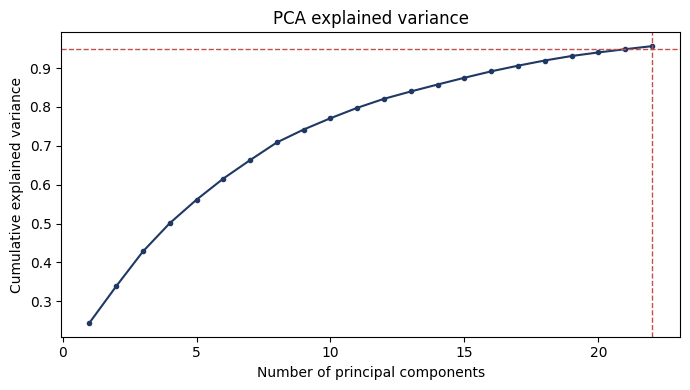

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, svd_solver="full", random_state=RANDOM_STATE).fit(X_train)   # train only
X_train_pca, X_test_pca = pca.transform(X_train), pca.transform(X_test)
print(f"{X_train.shape[1]} features -> {pca.n_components_} components "
      f"({pca.explained_variance_ratio_.sum():.1%} of variance)")

cum = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum, marker="o", ms=3, color="#1F3864")
plt.axhline(0.95, ls="--", c="#C0504D", lw=1); plt.axvline(pca.n_components_, ls="--", c="#C0504D", lw=1)
plt.xlabel("Number of principal components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance"); plt.tight_layout(); plt.show()

### Which original features drive each component?

For each component, the original feature with the largest absolute loading (`argmax` of `|components_|`).

In [17]:
names = np.array(feature_names)
pd.DataFrame({
    "component": range(1, 9),
    "variance_%": (pca.explained_variance_ratio_[:8] * 100).round(1),
    "top_feature": names[np.abs(pca.components_[:8]).argmax(axis=1)],
    "top3_features": [", ".join(names[np.argsort(np.abs(c))[::-1][:3]]) for c in pca.components_[:8]],
}).set_index("component")

,variance_%,top_feature,top3_features
component,,,
1,24.5,dwin,"dwin, swin, ct_dst_src_ltm"
2,9.4,dpkts,"dpkts, dloss, dbytes"
3,9.0,dpkts,"dpkts, dbytes, dloss"
4,7.3,sbytes,"sbytes, sloss, spkts"
5,6.0,dbytes,"dbytes, dloss, ct_state_ttl"
6,5.4,sinpkt,"sinpkt, is_sm_ips_ports, proto"
7,4.7,ct_ftp_cmd,"ct_ftp_cmd, is_ftp_login, is_sm_ips_ports"
8,4.5,sjit,"sjit, dinpkt, djit"


### Models on PCA features vs raw features

In [18]:
def timed_predict(m, X):
    t0 = time.time(); p = m.predict(X); return p, time.time() - t0

bin_pca_models, bin_pca_times = train_models("binary", X_train_pca, y_train_bin)
multi_pca_models, multi_pca_times = train_models("multiclass", X_train_pca, y_train_multi)

rows = []
for name in bin_models:
    p0, t0_ = timed_predict(bin_models[name], X_test)
    p1, t1_ = timed_predict(bin_pca_models[name], X_test_pca)
    rows.append(dict(model=name,
                     f1_raw=f1_score(y_test_bin, p0), f1_pca=f1_score(y_test_bin, p1),
                     precision_raw=precision_score(y_test_bin, p0), precision_pca=precision_score(y_test_bin, p1),
                     recall_raw=recall_score(y_test_bin, p0), recall_pca=recall_score(y_test_bin, p1),
                     predict_s_raw=t0_, predict_s_pca=t1_,
                     train_s_raw=bin_times[name], train_s_pca=bin_pca_times[name]))
bin_pca_cmp = pd.DataFrame(rows).set_index("model").round(4)
print("BINARY: raw features vs PCA features")
bin_pca_cmp

BINARY: raw features vs PCA features


,f1_raw,f1_pca,precision_raw,precision_pca,recall_raw,recall_pca,predict_s_raw,predict_s_pca,train_s_raw,train_s_pca
model,,,,,,,,,,
decision_tree,0.8739,0.8538,0.7871,0.7501,0.9822,0.9908,0.0095,0.0066,1.5287,3.6462
random_forest,0.8895,0.8656,0.8081,0.7688,0.9892,0.9904,0.4570,0.5082,21.7120,56.4101
xgboost,0.8960,0.8687,0.8204,0.7759,0.9869,0.9867,0.1091,0.1042,5.1684,2.2152
voting_ensemble,0.8904,0.8630,0.8112,0.7650,0.9866,0.9897,0.5468,0.6413,27.3557,60.9248


In [19]:
rows = []
for name in multi_models:
    p0, t0_ = timed_predict(multi_models[name], X_test)
    p1, t1_ = timed_predict(multi_pca_models[name], X_test_pca)
    rows.append(dict(model=name,
                     acc_raw=accuracy_score(y_test_multi, p0), acc_pca=accuracy_score(y_test_multi, p1),
                     macro_f1_raw=f1_score(y_test_multi, p0, average="macro", zero_division=0),
                     macro_f1_pca=f1_score(y_test_multi, p1, average="macro", zero_division=0),
                     predict_s_raw=t0_, predict_s_pca=t1_,
                     train_s_raw=multi_times[name], train_s_pca=multi_pca_times[name]))
multi_pca_cmp = pd.DataFrame(rows).set_index("model").round(4)
print("MULTI-CLASS: raw features vs PCA features")
multi_pca_cmp

MULTI-CLASS: raw features vs PCA features


,acc_raw,acc_pca,macro_f1_raw,macro_f1_pca,predict_s_raw,predict_s_pca,train_s_raw,train_s_pca
model,,,,,,,,
decision_tree,0.7031,0.7088,0.4431,0.3374,0.0124,0.0091,1.5951,3.9849
random_forest,0.7676,0.7247,0.4734,0.4019,0.6782,0.7100,23.3152,58.5850
xgboost,0.7691,0.7231,0.5023,0.4035,1.1412,1.1867,22.9031,20.0247
voting_ensemble,0.7565,0.7239,0.4708,0.3816,1.9030,1.9272,50.1087,85.0952


**Finding: PCA did not help. It lowered performance for every model and gave no meaningful speed-up.**

- **Binary:** F1 fell for all four models (XGBoost 0.896 to 0.869, Random Forest 0.890 to 0.866). Precision dropped (to about 0.75 to 0.78 from 0.79 to 0.82) while recall stayed about the same.
- **Multi-class:** the damage is larger. Macro-F1 fell by 0.07 to 0.11 for every model (XGBoost 0.502 to 0.404).
- **No meaningful speed-up:** prediction-time differences are small and mixed in direction (timings on a single CPU core are noisy). Training was slower for the tree models (Random Forest about 22s to 56s), likely because dense, continuous components give trees many more split candidates.
- **Why PCA hurts here (likely reasons):**
  1. PCA is unsupervised: it keeps the directions with the most *variance*, not the most *class information*. The loadings table shows the leading components are driven by volume and window features (`dwin`, `dpkts`, `sbytes`), i.e. whatever varies most, which is not necessarily what separates attacks from normal traffic.
  2. Tree models split on individual features. Rotating the data into blended components removes the clean, meaningful splits they rely on.
  3. The 5% of variance that is discarded can contain subtle patterns that separate rare attack classes, which fits the larger macro-F1 drop.
  4. `proto`, `service` and `state` are arbitrary integer codes, so mixing them into components has no real meaning.
- **Takeaway:** for tree-based ensembles on this dataset, raw features are better. PCA is more useful for distance-based or linear models, or when there are hundreds of correlated features.

## 5. Feature importance (Random Forest, multi-class)

In [20]:
pd.Series(multi_models["random_forest"].feature_importances_, index=feature_names) \
  .sort_values(ascending=False).head(10).round(4)

ct_dst_sport_ltm    0.0815
sbytes              0.0746
sttl                0.0733
ct_dst_src_ltm      0.0690
ct_srv_dst          0.0633
ct_state_ttl        0.0621
smean               0.0522
ct_src_dport_ltm    0.0447
ct_srv_src          0.0445
service             0.0405
dtype: float64

## 6. Save artifacts for `demo.py`

In [21]:
joblib.dump(encoders, ARTIFACTS / "encoders.pkl")
joblib.dump(scaler, ARTIFACTS / "scaler.pkl")
joblib.dump(feature_names, ARTIFACTS / "feature_names.pkl")
joblib.dump(label_encoder, ARTIFACTS / "label_encoder.pkl")
test_df.drop(columns=["id"]).to_csv(ARTIFACTS / "X_test_raw_sample.csv", index=False)

for task, models in [("binary", bin_models), ("multiclass", multi_models), ("multiclass_smote", smote_models),
                     ("binary_pca", bin_pca_models), ("multiclass_pca", multi_pca_models)]:
    d = ARTIFACTS / task; d.mkdir(exist_ok=True)
    for name, m in models.items():
        joblib.dump(m, d / f"{name}.pkl")
(ARTIFACTS / "pca").mkdir(exist_ok=True)
joblib.dump(pca, ARTIFACTS / "pca" / "pca.pkl")
# Result tables (results_summary.csv, per-class CSVs, plots) are written by train_pipeline.py
print("Saved. Run: python demo.py")

Saved. Run: python demo.py
